In [1]:
from pathlib import Path

data_dir = Path("data")

print("Images folder found:", (data_dir / "train_images").is_dir())
print("Labels file found:", (data_dir / "train.csv").is_file())
print("Disease names found:", (data_dir / "label_num_to_disease_map.json").is_file())

Images folder found: True
Labels file found: True
Disease names found: True


In [2]:
import csv

with (data_dir / "train.csv").open(newline="") as file:
    records = list(csv.DictReader(file))

missing_images = [
    row["image_id"]
    for row in records
    if not (data_dir / "train_images" / row["image_id"]).is_file()
]

print("Images listed in CSV:", len(records))
print("Missing images:", len(missing_images))
print("First record:", records[0])

Images listed in CSV: 21397
Missing images: 0
First record: {'image_id': '1000015157.jpg', 'label': '0'}


In [3]:
import json
from collections import Counter

with (data_dir / "label_num_to_disease_map.json").open() as file:
    disease_names = json.load(file)

label_counts = Counter(row["label"] for row in records)

for label in sorted(label_counts):
    count = label_counts[label]
    percentage = count / len(records) * 100
    print(f"{disease_names[label]}: {count:,} images ({percentage:.1f}%)")

Cassava Bacterial Blight (CBB): 1,087 images (5.1%)
Cassava Brown Streak Disease (CBSD): 2,189 images (10.2%)
Cassava Green Mottle (CGM): 2,386 images (11.2%)
Cassava Mosaic Disease (CMD): 13,158 images (61.5%)
Healthy: 2,577 images (12.0%)


In [4]:
%pip install Pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 2.0 MB/s  0:00:02 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


Filename: 1000015157.jpg
Dataset label: Cassava Bacterial Blight (CBB)
Original size: (800, 600)
Colour mode: RGB


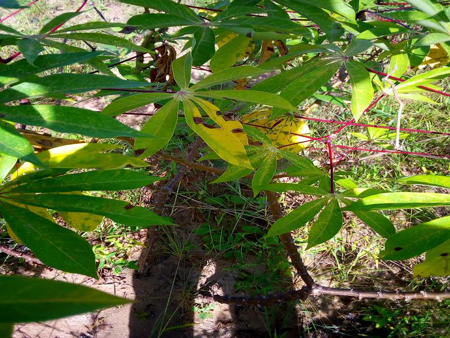

In [5]:
from PIL import Image
from IPython.display import display

record = records[0]
image_path = data_dir / "train_images" / record["image_id"]

print("Filename:", record["image_id"])
print("Dataset label:", disease_names[record["label"]])

with Image.open(image_path) as img:
    print("Original size:", img.size)
    print("Colour mode:", img.mode)

    preview = img.copy()
    preview.thumbnail((450, 450))
    display(preview)

In [6]:
image_sizes = Counter()
colour_modes = Counter()
unreadable_images = []

for index, record in enumerate(records, start=1):
    path = data_dir / "train_images" / record["image_id"]

    try:
        with Image.open(path) as img:
            img.load()  # Read the full image to check for decoding errors
            image_sizes[img.size] += 1
            colour_modes[img.mode] += 1

    except (OSError, ValueError) as error:
        unreadable_images.append((record["image_id"], str(error)))

    if index % 5000 == 0:
        print(f"Checked {index:,} images...")

print("\nCheck finished.")
print("Unreadable images:", len(unreadable_images))
print("Most common sizes:", image_sizes.most_common(5))
print("Colour modes:", dict(colour_modes))

if unreadable_images:
    print("First errors:", unreadable_images[:5])

Checked 5,000 images...
Checked 10,000 images...
Checked 15,000 images...
Checked 20,000 images...

Check finished.
Unreadable images: 0
Most common sizes: [((800, 600), 21397)]
Colour modes: {'RGB': 21397}


In [7]:
# Check for identical image files so duplicate copies can be kept
# out of separate training and test sets. No files are changed or deleted.

import hashlib
from collections import defaultdict

images_by_hash = defaultdict(list)

for index, record in enumerate(records, start=1):
    path = data_dir / "train_images" / record["image_id"]

    # A fingerprint of the file's contents, independent of its filename
    fingerprint = hashlib.sha256(path.read_bytes()).hexdigest()
    images_by_hash[fingerprint].append(record["image_id"])

    if index % 5000 == 0:
        print(f"Checked {index:,} files...")

duplicate_groups = [
    filenames
    for filenames in images_by_hash.values()
    if len(filenames) > 1
]

print("\nGroups of identical files:", len(duplicate_groups))
print("Extra duplicate copies:",
      sum(len(group) - 1 for group in duplicate_groups))
print("First 5 groups:", duplicate_groups[:5])

Checked 5,000 files...
Checked 10,000 files...
Checked 15,000 files...
Checked 20,000 files...

Groups of identical files: 0
Extra duplicate copies: 0
First 5 groups: []


In [8]:
# Check the labels table for missing values, unknown labels,
# and repeated filenames. This does not change the dataset.

missing_values = [
    row for row in records
    if not row["image_id"] or not row["label"]
]

unknown_labels = [
    row for row in records
    if row["label"] not in disease_names
]

filename_counts = Counter(row["image_id"] for row in records)
repeated_filenames = [
    name for name, count in filename_counts.items() if count > 1
]

print("Rows with missing values:", len(missing_values))
print("Rows with unknown labels:", len(unknown_labels))
print("Repeated filenames:", len(repeated_filenames))

Rows with missing values: 0
Rows with unknown labels: 0
Repeated filenames: 0



Cassava Bacterial Blight (CBB) — 1841269407.jpg


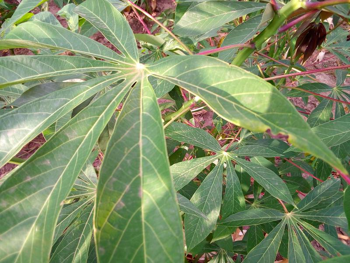


Cassava Brown Streak Disease (CBSD) — 1160441044.jpg


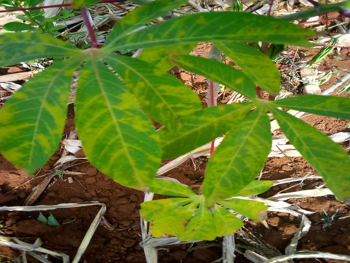


Cassava Green Mottle (CGM) — 2801727274.jpg


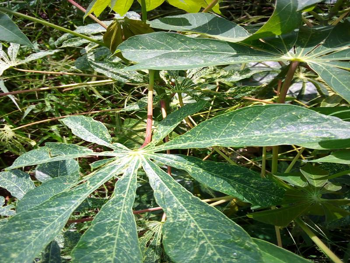


Cassava Mosaic Disease (CMD) — 2166936841.jpg


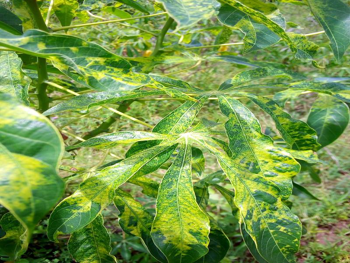


Healthy — 2325593465.jpg


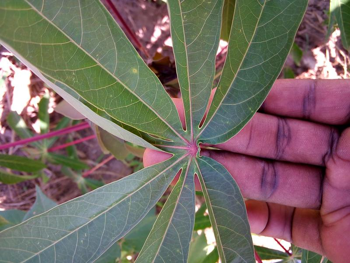

In [9]:
# Display one randomly selected image from each class.
# A fixed seed makes the selection repeatable. Original files stay unchanged.

import random

rng = random.Random(42)

for label, disease in sorted(disease_names.items()):
    class_records = [
        row for row in records if row["label"] == label
    ]
    sample = rng.choice(class_records)

    print(f"\n{disease} — {sample['image_id']}")

    with Image.open(data_dir / "train_images" / sample["image_id"]) as img:
        preview = img.copy()
        preview.thumbnail((350, 350))
        display(preview)

In [10]:
# Install a tool for comparing image appearance, so we can flag
# possible duplicate photos even when their file contents differ.

%pip install ImageHash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 2.1 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 2.2 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 1.8 MB/s  0:00:11m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ImageHash]/4 [PyWavelets]
Note: you may need to restart the kernel to use updated packages.


In [11]:
# Create visual fingerprints for finding possible duplicate photos.
# This reads the images without changing them.

import imagehash

visual_hashes = {}

for index, record in enumerate(records, start=1):
    filename = record["image_id"]
    path = data_dir / "train_images" / filename

    with Image.open(path) as img:
        visual_hashes[filename] = imagehash.phash(img.convert("RGB"))

    if index % 5000 == 0:
        print(f"Processed {index:,} images...")

print("\nVisual fingerprints created:", len(visual_hashes))

Processed 5,000 images...
Processed 10,000 images...
Processed 15,000 images...
Processed 20,000 images...

Visual fingerprints created: 21397


In [13]:
# Find image pairs with very similar visual fingerprints.
# Flag candidates for inspection; do not delete or change any images.

hash_values = [
    (filename, int(str(fingerprint), 16))
    for filename, fingerprint in visual_hashes.items()
]

buckets = defaultdict(list)
similar_pairs = []

for index, (filename, value) in enumerate(hash_values):
    # Compare likely matches efficiently instead of every possible pair.
    keys = [
        (band, (value >> (13 * band)) & 8191)
        for band in range(5)
    ]

    candidates = set()
    for key in keys:
        candidates.update(buckets[key])

    for previous_index in candidates:
        other_filename, other_value = hash_values[previous_index]
        difference = (value ^ other_value).bit_count()

        if difference <= 4:
            similar_pairs.append(
                (other_filename, filename, difference)
            )

    for key in keys:
        buckets[key].append(index)

similar_pairs.sort(key=lambda pair: (pair[2], pair[0], pair[1]))

print("Possible duplicate pairs:", len(similar_pairs))
print("\nFirst 10 pairs (filename, filename, difference):")
for pair in similar_pairs[:10]:
    print(pair)

Possible duplicate pairs: 0

First 10 pairs (filename, filename, difference):


In [14]:
# Split each disease class into roughly 70% training, 15% validation,
# and 15% testing. Only filename lists are created; images stay unchanged.

rng = random.Random(42)

train_records = []
val_records = []
test_records = []

for label in sorted(disease_names):
    class_records = [
        row for row in records if row["label"] == label
    ]
    rng.shuffle(class_records)

    train_end = round(len(class_records) * 0.70)
    val_end = train_end + round(len(class_records) * 0.15)

    train_records.extend(class_records[:train_end])
    val_records.extend(class_records[train_end:val_end])
    test_records.extend(class_records[val_end:])

for split in (train_records, val_records, test_records):
    rng.shuffle(split)

print("Training images:", len(train_records))
print("Validation images:", len(val_records))
print("Test images:", len(test_records))
print("Total:", len(train_records) + len(val_records) + len(test_records))

Training images: 14978
Validation images: 3210
Test images: 3209
Total: 21397


In [15]:
# Check that the training, validation, and test sets do not overlap,
# and together contain every image from the original labels table.

train_ids = {row["image_id"] for row in train_records}
val_ids = {row["image_id"] for row in val_records}
test_ids = {row["image_id"] for row in test_records}
all_ids = {row["image_id"] for row in records}

assert len(train_ids) == len(train_records)
assert len(val_ids) == len(val_records)
assert len(test_ids) == len(test_records)

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert train_ids | val_ids | test_ids == all_ids

print("Checks passed: no repeated filenames or overlap.")
print("Every image belongs to exactly one split.")

Checks passed: no repeated filenames or overlap.
Every image belongs to exactly one split.


In [16]:
# Save the verified splits as CSV files so they can be reused
# across models and experiments without moving or copying images.

split_dir = Path("splits")
split_dir.mkdir(exist_ok=True)

split_records = {
    "train": train_records,
    "validation": val_records,
    "test": test_records,
}

for name, rows in split_records.items():
    output_path = split_dir / f"{name}.csv"

    with output_path.open("w", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=["image_id", "label"])
        writer.writeheader()
        writer.writerows(rows)

    print(f"Saved {output_path}: {len(rows):,} rows")

Saved splits/train.csv: 14,978 rows
Saved splits/validation.csv: 3,210 rows
Saved splits/test.csv: 3,209 rows


In [17]:
# Calculate class weights from the training set to give
# less common classes more influence during model training.

train_counts = Counter(row["label"] for row in train_records)
num_classes = len(disease_names)

class_weights = {
    int(label): len(train_records) / (num_classes * count)
    for label, count in train_counts.items()
}

for label, weight in sorted(class_weights.items()):
    print(f"{disease_names[str(label)]}: {weight:.3f}")

Cassava Bacterial Blight (CBB): 3.936
Cassava Brown Streak Disease (CBSD): 1.955
Cassava Green Mottle (CGM): 1.794
Cassava Mosaic Disease (CMD): 0.325
Healthy: 1.661


In [18]:
# Save class weights, label meanings, and split settings
# so future training runs can use the same configuration.

training_config = {
    "split_seed": 42,
    "split_fractions": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15,
    },
    "label_to_disease": disease_names,
    "training_class_counts": dict(train_counts),
    "class_weights": class_weights,
    "class_weight_formula": "training_total / (num_classes * class_count)",
}

config_path = split_dir / "training_config.json"

with config_path.open("w") as file:
    json.dump(training_config, file, indent=2)

print("Saved:", config_path)

Saved: splits/training_config.json


In [19]:
# Check that all five classes appear in every split
# with approximately the same proportions as the full dataset.

for split_name, rows in split_records.items():
    counts = Counter(row["label"] for row in rows)
    print(f"\n{split_name.upper()} — {len(rows):,} images")

    for label, disease in sorted(disease_names.items()):
        count = counts[label]
        percentage = count / len(rows) * 100
        print(f"  {disease}: {count:,} ({percentage:.1f}%)")

    assert set(counts) == set(disease_names), "A class is missing!"


TRAIN — 14,978 images
  Cassava Bacterial Blight (CBB): 761 (5.1%)
  Cassava Brown Streak Disease (CBSD): 1,532 (10.2%)
  Cassava Green Mottle (CGM): 1,670 (11.1%)
  Cassava Mosaic Disease (CMD): 9,211 (61.5%)
  Healthy: 1,804 (12.0%)

VALIDATION — 3,210 images
  Cassava Bacterial Blight (CBB): 163 (5.1%)
  Cassava Brown Streak Disease (CBSD): 328 (10.2%)
  Cassava Green Mottle (CGM): 358 (11.2%)
  Cassava Mosaic Disease (CMD): 1,974 (61.5%)
  Healthy: 387 (12.1%)

TEST — 3,209 images
  Cassava Bacterial Blight (CBB): 163 (5.1%)
  Cassava Brown Streak Disease (CBSD): 329 (10.3%)
  Cassava Green Mottle (CGM): 358 (11.2%)
  Cassava Mosaic Disease (CMD): 1,973 (61.5%)
  Healthy: 386 (12.0%)


Dataset label: Healthy
Original dimensions: (800, 600)
Resized dimensions: (224, 224)


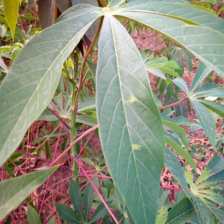

In [20]:
# Preview a training image resized to the paper's 224 × 224 input size.
# This directly resizes the image; the original file stays unchanged.

sample = train_records[0]
image_path = data_dir / "train_images" / sample["image_id"]

with Image.open(image_path) as img:
    original = img.convert("RGB")
    resized = original.resize(
        (224, 224),
        resample=Image.Resampling.BILINEAR
    )

    print("Dataset label:", disease_names[sample["label"]])
    print("Original dimensions:", original.size)
    print("Resized dimensions:", resized.size)
    display(resized)